In [2]:
# Step 1: Import library

import pandas as pd

# Load dataset

df = pd.read_csv('/content/superstore_orders_exp6.csv')

# Display first five rows

df.head()


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


In [3]:
# Check dataset shape

print("Dataset Shape:", df.shape)

# Display column names

print("\nColumn Names:")
print(df.columns.tolist())

# Check missing values

print("\nMissing Values:")
print(df.isnull().sum())

# Dataset information

print("\nDataset Information:")
df.info()

Dataset Shape: (10194, 21)

Column Names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Missing Values:
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country/Region    0
City              0
State/Province    0
Postal Code       0
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
dtype: int64

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID

In [4]:
# Select input features

features = df[
    ['Sales', 'Quantity', 'Discount',
     'Category', 'Sub-Category', 'Region']
]

# Apply One-Hot Encoding

X = pd.get_dummies(
    features,
    columns=['Category', 'Sub-Category', 'Region'],
    drop_first=True
)

# Select target variable

y = df['Profit']

# Display encoded features

print("Encoded Features:")
display(X.head())

print("\nTarget Variable:")
display(y.head())

print("\nFeatures Shape:", X.shape)
print("Target Shape:", y.shape)

Encoded Features:


,Sales,Quantity,Discount,Category_Office Supplies,Category_Technology,Sub-Category_Appliances,Sub-Category_Art,Sub-Category_Binders,Sub-Category_Bookcases,Sub-Category_Chairs,...,Sub-Category_Labels,Sub-Category_Machines,Sub-Category_Paper,Sub-Category_Phones,Sub-Category_Storage,Sub-Category_Supplies,Sub-Category_Tables,Region_East,Region_South,Region_West
0,16.448,2,0.2,True,False,False,False,False,False,False,...,False,False,True,False,False,False,False,False,False,False
1,3.540,2,0.8,True,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False
2,11.784,3,0.2,True,False,False,False,False,False,False,...,True,False,False,False,False,False,False,False,False,False
3,272.736,3,0.2,True,False,False,False,False,False,False,...,False,False,False,False,True,False,False,False,False,False
4,19.536,3,0.2,True,False,False,True,False,False,False,...,False,False,False,False,False,False,False,True,False,False



Target Variable:


,Profit
0,5.5512
1,-5.4870
2,4.2717
3,-64.7748
4,4.8840



Features Shape: (10194, 24)
Target Shape: (10194,)


In [5]:
# Import train_test_split

from sklearn.model_selection import train_test_split

# Split the dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Display dataset sizes

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Data: (8155, 24)
Testing Data: (2039, 24)

Training Target: (8155,)
Testing Target: (2039,)


In [6]:
# Import Linear Regression

from sklearn.linear_model import LinearRegression

# Create model

model = LinearRegression()

# Train the model

model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

# Predict profit

predictions = model.predict(X_test)

print("\nPredicted Profit:")
print(predictions[:10])

Linear Regression Model Trained Successfully!

Predicted Profit:
[-101.32803505  -15.60244716   17.94545731  105.1928154   171.77545295
  288.91760892   43.21750762   59.67534845   23.811943    117.75918511]


In [7]:
# Import evaluation metrics

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

import numpy as np

# Calculate R2 score

r2 = r2_score(y_test, predictions)

# Calculate MAE

mae = mean_absolute_error(y_test, predictions)

# Calculate RMSE

rmse = np.sqrt(
    mean_squared_error(y_test, predictions)
)

# Display results

print("Model Evaluation Results")

print("-------------------------")

print("R2 Score:", r2)

print("MAE:", mae)

print("RMSE:", rmse)

Model Evaluation Results
-------------------------
R2 Score: 0.4893557202229447
MAE: 61.75773215703767
RMSE: 214.0514331410141


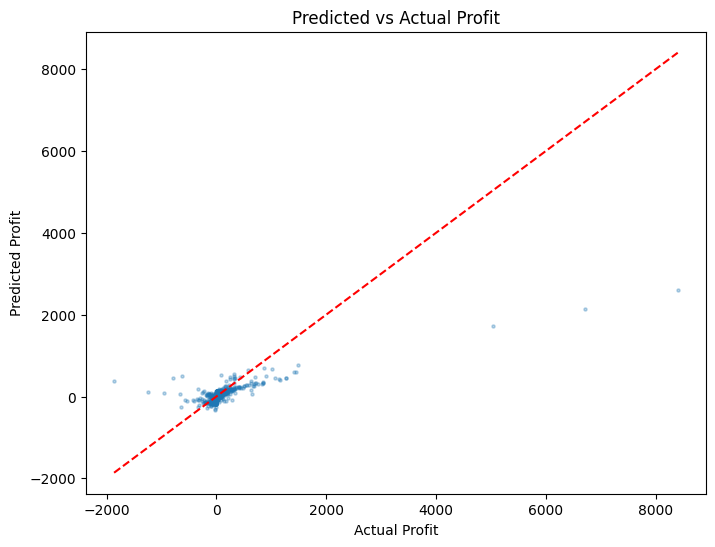

In [8]:
import matplotlib.pyplot as plt

# Create scatter plot

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    predictions,
    s=5,
    alpha=0.3
)

# Draw red diagonal line

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

# Add labels and title

plt.xlabel('Actual Profit')

plt.ylabel('Predicted Profit')

plt.title('Predicted vs Actual Profit')

plt.show()

In [9]:
# Compare actual and predicted profit

comparison = pd.DataFrame({
    'Actual Profit': y_test.values,
    'Predicted Profit': predictions
})

display(comparison.head(10))

,Actual Profit,Predicted Profit
0,-14.3313,-101.328035
1,4.7712,-15.602447
2,-7.7094,17.945457
3,108.1752,105.192815
4,218.2518,171.775453
5,585.5520,288.917609
6,48.9645,43.217508
7,20.6820,59.675348
8,1.7876,23.811943
9,28.0032,117.759185


In [11]:
print("========== EXPERIMENT 6 RESULTS ==========")

print("Total Records:", len(df))

print("Training Records:", len(X_train))

print("Testing Records:", len(X_test))

print("\nModel Performance:")

print("R2 Score:", round(r2, 4))

print("MAE:", round(mae, 4))

print("RMSE:", round(rmse, 4))

print("\nModel:", "Linear Regression")

print("Target Variable:", "Profit")

print("\nExperiment Completed Successfully!")

========== EXPERIMENT 6 RESULTS ==========
Total Records: 10194
Training Records: 8155
Testing Records: 2039

Model Performance:
R2 Score: 0.4894
MAE: 61.7577
RMSE: 214.0514

Model: Linear Regression
Target Variable: Profit

Experiment Completed Successfully!
